In [29]:
# import the necessary libraries
import numpy as np
import matplotlib.pyplot as plt


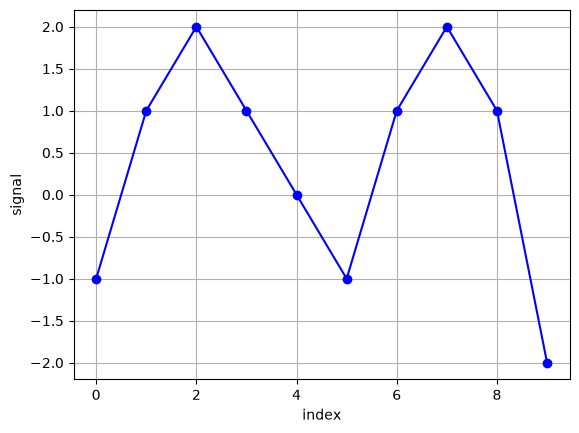

In [30]:
# Create functions to find and plot remarkable points
# plot with remarkable points

index = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])
plt.plot(index, signal, marker='o', linestyle='-', color='b')    
plt.xlabel('index')
plt.ylabel('signal')
plt.grid()



In [31]:
# create a function to find zero crossings in a sign array without zeros
def find_zero_crossings_no_zeros(signs: np.ndarray): 
    """Find zero crossings in a sign array without zeros"""
    diff = np.diff(signs) #np.diff calculates the difference between consecutive elements in the array. 
    i_cross_pos = np.where(diff > 0)[0] #indices where the difference is positive, indicating a zero crossing from negative to positive.
    i_cross_neg = np.where(diff < 0)[0] # indices where the difference is negative, indicating a zero crossing from positive to negative.
    return i_cross_pos, i_cross_neg



In [32]:
# create a function to propagate non-zero signs over zero positions in the sign array
# replace zeros with the last non-zero sign encountered in the array
def propagate_signs_over_zeros(signs: np.ndarray):
    """Propagate non-zero signs over zero positions in the sign array."""

    signs_no_zeros = signs.copy() #create a copy of the input sign array to avoid modifying the original array.

    mask = signs_no_zeros != 0 # create a boolean mask that identifies the positions of non-zero elements in the sign array. True ≠0, False = 0
    idx = np.where(mask, np.arange(len(signs_no_zeros)), 0) # create an array of indices where non-zero elements are located. For non-zero elements, it stores their indices; for zero elements, it stores 0.   
    idx = np.maximum.accumulate(idx) # compute the cumulative maximum of the index array, effectively propagating the last non-zero index forward to fill in the positions of zeros. This ensures that each zero position will be replaced by the last non-zero sign encountered in the array.
    signs_no_zeros = signs_no_zeros[idx] # replace the zero positions in the sign array with the corresponding non-zero signs based on the propagated indices.

    if signs_no_zeros[0] == 0: # particular case of the first element being zero, we need to find the first non-zero sign and propagate it backward to fill in the initial zeros.
        i_first_nonzero = np.where(signs != 0)[0]
        if len(i_first_nonzero) > 0:
            signs_no_zeros[: i_first_nonzero[0]] = signs[i_first_nonzero[0]]

    return signs_no_zeros

In [33]:
#use the above functions (find_zero_crossings_no_zeros, propagate_signs_over_zeros) to find zero crossings in a 1D signal array
def find_zero_crossings(s: np.ndarray): # s is signal 
    """Find zero crossings in a 1D signal array."""
#condition to check if the input signal is a 1D array. If not, it raises a ValueError.
    s = np.asarray(s)
    if s.ndim != 1: # if number of dimensions of s is different from 1
        raise ValueError("Input must be a 1D array")
# transform signal into sign (-1 for negative values, 0 for zero, 1 for positive values)
    signs = np.sign(s).astype(int)
# identitfy the index of values equal to 0
    i_zeros = np.where(signs == 0)[0]
# if there are values=0, call for the previous function to propagate non-zero signs over zero positions 
    if i_zeros.size > 0: # .size returns the number of elements in the array. If there are any zeros, it will be greater than 0.
        signs_no_zeros = propagate_signs_over_zeros(signs)
    else:
        signs_no_zeros = signs
# return the indicce of zero crossing, taking care of 0 signal value
    return find_zero_crossings_no_zeros(signs_no_zeros)

In [ ]:
# verify the function with some test cases
def test_find_zero_crossings():
    """Unit tests for find_zero_crossings function."""
    s = np.array([-1, 1, -1, 1, -1])
    # expected     +  -   +  -   +
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([0, 2])) # - to + crossings at indices 0 and 2
    assert np.array_equal(i_neg, np.array([1, 3])) # + to - crossings at indices 1 and 3

    s = np.array([-1, 0, 0, 1, 0, -1])
    # expected     -     +     -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([2]))
    assert np.array_equal(i_neg, np.array([4]))

    s = np.array([0, 0, 0, 1, 0, 0])
    # expected    no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([0, 0, 1, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([0, 1, 0, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([1, 0, 0, -1, 0, 0])
    # expected          -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([2]))


# Testing the function
try:
    test_find_zero_crossings()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error

All tests passed.
